# Step 1

## Team Member A

In [ ]:
# Team A: European option pricing with CRR binomial tree (N=100)


import math
import pandas as pd

# Parameters
S0 = 100.0
r = 0.05            # continuous annual rate
sigma_base = 0.20   # base volatility
sigma_up = 0.25     # increased volatility for vega test
T = 0.25            # 3 months = 0.25 year
N = 100             # number of binomial steps
dt = T / N

def binomial_crr_price(S0, K, r, sigma, T, N, option_type='call', american=False):
    """
    CRR binomial tree pricer for European (american=False) or American (american=True) options.
    Returns:
      - option price at root,
      - tuple(option_value_at_first_up_node, option_value_at_first_down_node) for delta calc,
      - u, d, p (tree params)
    """
    dt = T / N
    u = math.exp(sigma * math.sqrt(dt))
    d = 1 / u
    p = (math.exp(r * dt) - d) / (u - d)

    # Stock prices at maturity (vector) and payoff at maturity
    ST = [S0 * (u ** j) * (d ** (N - j)) for j in range(N + 1)]
    if option_type == 'call':
        payoffs = [max(s - K, 0.0) for s in ST]
    else:
        payoffs = [max(K - s, 0.0) for s in ST]

    # Backward induction for option values
    option_values = payoffs[:]
    for i in range(N - 1, -1, -1):
        option_values = [math.exp(-r * dt) * (p * option_values[j + 1] + (1 - p) * option_values[j])
                         for j in range(i + 1)]
        if american:
            # allow early exercise at each node
            for j in range(i + 1):
                S_ij = S0 * (u ** j) * (d ** (i - j))
                intrinsic = (max(S_ij - K, 0.0) if option_type == 'call' else max(K - S_ij, 0.0))
                option_values[j] = max(option_values[j], intrinsic)

    # To compute delta, capture option values at first-step up/down nodes.
    # Recompute and store values when i == 1
    option_values_repro = payoffs[:]
    first_step_vals = None
    for i in range(N - 1, -1, -1):
        option_values_repro = [math.exp(-r * dt) * (p * option_values_repro[j + 1] + (1 - p) * option_values_repro[j])
                                for j in range(i + 1)]
        if american:
            for j in range(i + 1):
                S_ij = S0 * (u ** j) * (d ** (i - j))
                intrinsic = (max(S_ij - K, 0.0) if option_type == 'call' else max(K - S_ij, 0.0))
                option_values_repro[j] = max(option_values_repro[j], intrinsic)
        if i == 1:
            first_step_vals = (option_values_repro[1], option_values_repro[0])

    return option_values[0], first_step_vals, u, d, p

K = S0

call_price, (call_up, call_down), u, d, p = binomial_crr_price(S0, K, r, sigma_base, T, N, option_type='call', american=False)
put_price, (put_up, put_down), _, _, _ = binomial_crr_price(S0, K, r, sigma_base, T, N, option_type='put', american=False)

S_u = S0 * u
S_d = S0 * d
delta_call = (call_up - call_down) / (S_u - S_d)
delta_put = (put_up - put_down) / (S_u - S_d)

# Vega approximation: reprice with sigma_up (25%) and take difference
call_price_up, _, _, _, _ = binomial_crr_price(S0, K, r, sigma_up, T, N, option_type='call', american=False)
put_price_up,  _, _, _, _ = binomial_crr_price(S0, K, r, sigma_up, T, N, option_type='put', american=False)

# Round prices to nearest cent (as required)
call_price_rounded = round(call_price + 1e-12, 2)
put_price_rounded = round(put_price + 1e-12, 2)
call_price_up_rounded = round(call_price_up + 1e-12, 2)
put_price_up_rounded = round(put_price_up + 1e-12, 2)

call_vega_abs = call_price_up - call_price
put_vega_abs = put_price_up - put_price

# Tabular result
df = pd.DataFrame({
    "Option": ["European Call (ATM, K=100)", "European Put (ATM, K=100)"],
    "Price (σ=20%)": [f"${call_price_rounded:.2f}", f"${put_price_rounded:.2f}"],
    "Price (σ=25%)": [f"${call_price_up_rounded:.2f}", f"${put_price_up_rounded:.2f}"],
    "Absolute Change (σ +5pp)": [f"${round(call_vega_abs, 4):.4f}", f"${round(put_vega_abs, 4):.4f}"],
    "Delta (approx)": [round(delta_call, 6), round(delta_put, 6)]
})

print(df.to_string(index=False))

# Optional: print internal tree params for reproducibility
print("\nTree params: u={:.12f}, d={:.12f}, p={:.12f}".format(u, d, p))


                    Option Price (σ=20%) Price (σ=25%) Absolute Change (σ +5pp)  Delta (approx)
European Call (ATM, K=100)         $4.61         $5.59                  $0.9809         0.56929
 European Put (ATM, K=100)         $3.36         $4.34                  $0.9809        -0.43071

Tree params: u=1.010050167084, d=0.990049833749, p=0.503750307302


## Team Member B

In [ ]:
import numpy as np

def binomial_tree_pricer(S0, K, T, r, sigma, N, option_type, style):
    """
    Prices European or American options using a binomial tree.
    Returns the option price and the delta at time 0.
    """
    # 1. Calculate tree parameters
    dt = T / N
    u = np.exp(sigma * np.sqrt(dt))
    d = 1 / u
    p = (np.exp(r * dt) - d) / (u - d)

    # 2. Initialize asset price and option value trees
    stock_tree = np.zeros((N + 1, N + 1))
    option_tree = np.zeros((N + 1, N + 1))
    stock_tree[0, 0] = S0

    # 3. Fill the stock price tree (forward induction)
    for j in range(1, N + 1):
        for i in range(j + 1):
            stock_tree[i, j] = S0 * (u**(j - i)) * (d**i)

    # 4. Calculate option payoff at maturity
    if option_type == 'call':
        option_tree[:, N] = np.maximum(0, stock_tree[:, N] - K)
    else: # put
        option_tree[:, N] = np.maximum(0, K - stock_tree[:, N])

    # 5. Calculate option values at earlier nodes (backward induction)
    for j in range(N - 1, -1, -1):
        for i in range(j + 1):
            hold_value = (p * option_tree[i, j + 1] + (1 - p) * option_tree[i + 1, j + 1]) * np.exp(-r * dt)
            if style == 'american':
                exercise_value = 0
                if option_type == 'call':
                    exercise_value = np.maximum(0, stock_tree[i, j] - K)
                else: # put
                    exercise_value = np.maximum(0, K - stock_tree[i, j])
                option_tree[i, j] = np.maximum(hold_value, exercise_value)
            else: # european
                option_tree[i, j] = hold_value

    # 6. Calculate Delta at time 0
    delta = (option_tree[0, 1] - option_tree[1, 1]) / (stock_tree[0, 1] - stock_tree[1, 1])

    return option_tree[0, 0], delta

# --- Shared Parameters ---
S0 = 100
r = 0.05
sigma = 0.20
T = 0.25 # 3 months

# Q8: Price an ATM American call and put
K_atm = 100
N_steps = 100 # Chosen number of steps

am_call_price, _ = binomial_tree_pricer(S0, K_atm, T, r, sigma, N_steps, 'call', 'american')
am_put_price, _ = binomial_tree_pricer(S0, K_atm, T, r, sigma, N_steps, 'put', 'american')

# Q9: Compute Delta for the American options
_, am_call_delta = binomial_tree_pricer(S0, K_atm, T, r, sigma, N_steps, 'call', 'american')
_, am_put_delta = binomial_tree_pricer(S0, K_atm, T, r, sigma, N_steps, 'put', 'american')

# Q10: Compute Vega sensitivity for American options
sigma_new = 0.25 # 5% increase in volatility
am_call_price_vega, _ = binomial_tree_pricer(S0, K_atm, T, r, sigma_new, N_steps, 'call', 'american')
am_put_price_vega, _ = binomial_tree_pricer(S0, K_atm, T, r, sigma_new, N_steps, 'put', 'american')

# --- Print Results ---
print("--- Question 8: American Option Pricing (ATM, N=100) ---")
print(f"a. Chosen number of steps: {N_steps}")
print(f"\nAmerican Call Price: ${am_call_price:.4f}")
print(f"American Put Price:  ${am_put_price:.4f}\n")

print("--- Question 9: American Option Delta (ATM) ---")
print(f"American Call Delta: {am_call_delta:.4f}")
print(f"American Put Delta:  {am_put_delta:.4f}")

print("--- Question 10: American Option Vega Sensitivity ---")
print(f"Original American Call Price (σ=20%): ${am_call_price:.4f}")
print(f"New American Call Price (σ=25%):      ${am_call_price_vega:.4f}")
print(f"Price Change (Vega effect) for Call:  +${am_call_price_vega - am_call_price:.4f}\n")
print(f"Original American Put Price (σ=20%): ${am_put_price:.4f}")
print(f"New American Put Price (σ=25%):      ${am_put_price_vega:.4f}")
print(f"Price Change (Vega effect) for Put:   +${am_put_price_vega - am_put_price:.4f}\n")

--- Question 8: American Option Pricing (ATM, N=100) ---
a. Chosen number of steps: 100

American Call Price: $4.6050
American Put Price:  $3.4746

--- Question 9: American Option Delta (ATM) ---
American Call Delta: 0.5693
American Put Delta:  -0.4498
--- Question 10: American Option Vega Sensitivity ---
Original American Call Price (σ=20%): $4.6050
New American Call Price (σ=25%):      $5.5860
Price Change (Vega effect) for Call:  +$0.9809

Original American Put Price (σ=20%): $3.4746
New American Put Price (σ=25%):      $4.4528
Price Change (Vega effect) for Put:   +$0.9783



## Team Member C

In [ ]:
# ================================
# STEP 1 — MEMBER C (Binomial CRR)
# Q11: European Put–Call Parity (ATM)
# Q12: American Put–Call “Parity” (ATM)
# Q13: Confirm C_E ≤ C_A (calls) with numbers
# Q14: Confirm P_E ≤ P_A (puts) with numbers
# - Uses CRR with N=100 (aligns with Members A & B)
# - Displays team-reported premiums where provided; also prints computed values for transparency
# ================================

import math
import numpy as np
import pandas as pd

def crr_price(S0, K, T, r, sigma, N, is_call=True, american=False):
    """Cox–Ross–Rubinstein binomial pricer (continuous r; early exercise if american=True)."""
    dt = T / N
    u  = math.exp(sigma * math.sqrt(dt))
    d  = 1.0 / u
    p  = (math.exp(r * dt) - d) / (u - d)
    disc = math.exp(-r * dt)

    # terminal payoffs
    ST = [S0 * (u**j) * (d**(N - j)) for j in range(N + 1)]
    vals = [max(s - K, 0.0) if is_call else max(K - s, 0.0) for s in ST]

    # backward induction (with early exercise if American)
    for j in range(N - 1, -1, -1):
        vals = [disc * (p * vals[i + 1] + (1 - p) * vals[i]) for i in range(j + 1)]
        if american:
            for i in range(j + 1):
                Sij = S0 * (u**(j - i)) * (d**i)
                ex  = max(Sij - K, 0.0) if is_call else max(K - Sij, 0.0)
                vals[i] = max(vals[i], ex)
    return vals[0]

# ---- Team parameters (align with Members A & B) ----
S0    = 100.0
K_atm = 100.0
r     = 0.05
sigma = 0.20
T     = 0.25
N     = 100

print(f"\n[STEP 1] Binomial CRR settings: N={N}, S0={S0}, K={K_atm}, r={r}, sigma={sigma}, T={T}")

# ---- Compute CRR prices (ground truth) ----
C_E_calc = crr_price(S0, K_atm, T, r, sigma, N, is_call=True,  american=False)
P_E_calc = crr_price(S0, K_atm, T, r, sigma, N, is_call=False, american=False)
C_A_calc = crr_price(S0, K_atm, T, r, sigma, N, is_call=True,  american=True)
P_A_calc = crr_price(S0, K_atm, T, r, sigma, N, is_call=False, american=True)

# ---- Team-reported premiums (to substitute into the narrative) ----
# Member A (European):
REPORTED_EUR_CALL = 4.61
REPORTED_EUR_PUT  = 3.36
# Member B (American):
REPORTED_AM_CALL  = 4.6050
REPORTED_AM_PUT   = 3.4746

USE_REPORTED_FOR_DISPLAY = True  # set False to show only computed values in the narrative

C_E_disp = REPORTED_EUR_CALL if USE_REPORTED_FOR_DISPLAY else C_E_calc
P_E_disp = REPORTED_EUR_PUT  if USE_REPORTED_FOR_DISPLAY else P_E_calc
C_A_disp = REPORTED_AM_CALL  if USE_REPORTED_FOR_DISPLAY else C_A_calc
P_A_disp = REPORTED_AM_PUT   if USE_REPORTED_FOR_DISPLAY else P_A_calc

# =========================
# Q11: European Put–Call Parity (ATM)
# =========================
PVK = K_atm * math.exp(-r * T)
lhs_disp = C_E_disp - P_E_disp
rhs      = S0 - PVK
gap_disp = lhs_disp - rhs

print("\n=== STEP 1 — Q11: European Put–Call Parity (Binomial CRR) ===")
print(f"Reported Call premium (C_E): ${C_E_disp:.2f}")
print(f"Reported Put  premium (P_E): ${P_E_disp:.2f}")
print(f"PV(K)                      : {PVK:.4f}")
print(f"LHS = C_E - P_E            : {lhs_disp:.4f}")
print(f"RHS = S0 - PV(K)           : {rhs:.4f}")
print(f"Gap (LHS-RHS)              : {gap_disp:.4f}")
print("Result: Parity {} within ±0.02."
      .format("holds" if abs(gap_disp) <= 0.02 else "does NOT hold"))

# (Also show computed values for transparency)
print("\n[Computed (CRR) values for reference]")
print(f"C_E_calc=${C_E_calc:.4f}, P_E_calc=${P_E_calc:.4f}, (C_E-P_E)={C_E_calc-P_E_calc:.4f}")

# ==================================
# Q12: American “parity” (ATM demonstration)
# ==================================
lhsA_disp = C_A_disp - P_A_disp
gapA_disp = lhsA_disp - rhs

print("\n=== STEP 1 — Q12: American Put–Call (Binomial CRR) ===")
print(f"Reported Call premium (C_A): ${C_A_disp:.4f}")
print(f"Reported Put  premium (P_A): ${P_A_disp:.4f}")
print(f"LHS = C_A - P_A            : {lhsA_disp:.4f}")
print(f"RHS = S0 - PV(K)           : {rhs:.4f}")
print(f"Gap (LHS-RHS)              : {gapA_disp:.4f}")
print("Result: Exact parity need not hold for Americans (puts may be exercised early; "
      "calls (no dividends) should not be).")

# (Also show computed values for reference)
print("\n[Computed (CRR) values for reference]")
print(f"C_A_calc=${C_A_calc:.4f}, P_A_calc=${P_A_calc:.4f}, (C_A-P_A)={C_A_calc-P_A_calc:.4f}")

# ===========================================
# Q13 & Q14: Numerical confirmations across K (computed)
# ===========================================
K_list = [90.0, 95.0, 100.0, 105.0, 110.0]
C_Es = [crr_price(S0, K, T, r, sigma, N, True,  american=False) for K in K_list]
P_Es = [crr_price(S0, K, T, r, sigma, N, False, american=False) for K in K_list]
C_As = [crr_price(S0, K, T, r, sigma, N, True,  american=True)  for K in K_list]
P_As = [crr_price(S0, K, T, r, sigma, N, False, american=True)  for K in K_list]

df_ineq = pd.DataFrame({
    "Strike K": K_list,
    "C_A − C_E (calls, expected ≥ 0)": [round(ca - ce, 4) for ca, ce in zip(C_As, C_Es)],
    "P_A − P_E (puts,  expected ≥ 0)": [round(pa - pe, 4) for pa, pe in zip(P_As, P_Es)],
})
print("\n=== STEP 1 — Q13 & Q14: Inequalities (Binomial CRR) ===")
print(df_ineq.to_string(index=False))

ok_calls = all((ca - ce) >= -1e-3 for ca, ce in zip(C_As, C_Es))  # tiny tolerance for rounding
ok_puts  = all((pa - pe) >= -1e-3 for pa, pe in zip(P_As, P_Es))
print(f"\nQ13 confirmation (C_A ≥ C_E): {'Yes' if ok_calls else 'No (check table)'}")
print(f"Q14 confirmation (P_A ≥ P_E): {'Yes' if ok_puts  else 'No (check table)'}")
print("Reason: No dividends ⇒ early exercise of calls is suboptimal (C_A ≈ C_E), "
      "but early exercise can add value to puts (P_A ≥ P_E).\n")



[STEP 1] Binomial CRR settings: N=100, S0=100.0, K=100.0, r=0.05, sigma=0.2, T=0.25

=== STEP 1 — Q11: European Put–Call Parity (Binomial CRR) ===
Reported Call premium (C_E): $4.61
Reported Put  premium (P_E): $3.36
PV(K)                      : 98.7578
LHS = C_E - P_E            : 1.2500
RHS = S0 - PV(K)           : 1.2422
Gap (LHS-RHS)              : 0.0078
Result: Parity holds within ±0.02.

[Computed (CRR) values for reference]
C_E_calc=$4.6050, P_E_calc=$3.3628, (C_E-P_E)=1.2422

=== STEP 1 — Q12: American Put–Call (Binomial CRR) ===
Reported Call premium (C_A): $4.6050
Reported Put  premium (P_A): $3.4746
LHS = C_A - P_A            : 1.1304
RHS = S0 - PV(K)           : 1.2422
Gap (LHS-RHS)              : -0.1118
Result: Exact parity need not hold for Americans (puts may be exercised early; calls (no dividends) should not be).

[Computed (CRR) values for reference]
C_A_calc=$8.4313, P_A_calc=$7.4105, (C_A-P_A)=1.0209

=== STEP 1 — Q13 & Q14: Inequalities (Binomial CRR) ===
 Strik

# Step 2

## Team Member B

In [1]:
import numpy as np
import pandas as pd

def trinomial_tree_pricer(S0, K, T, r, sigma, N, option_type):
    """
    Prices European options using a trinomial tree.
    """
    # 1. Calculate tree parameters (using Kamrad-Ritchken model)
    dt = T / N
    u = np.exp(sigma * np.sqrt(2 * dt))
    d = 1 / u

    pu = ((np.exp(r * dt / 2) - np.exp(-sigma * np.sqrt(dt / 2))) / \
          (np.exp(sigma * np.sqrt(dt / 2)) - np.exp(-sigma * np.sqrt(dt / 2))))**2
    pd = ((np.exp(sigma * np.sqrt(dt / 2)) - np.exp(r * dt / 2)) / \
          (np.exp(sigma * np.sqrt(dt / 2)) - np.exp(-sigma * np.sqrt(dt / 2))))**2
    pm = 1 - pu - pd

    # 2. Initialize asset price and option value trees
    # At each step j, there are 2j+1 nodes
    stock_tree = [np.zeros(2 * j + 1) for j in range(N + 1)]
    option_tree = [np.zeros(2 * j + 1) for j in range(N + 1)]
    stock_tree[0][0] = S0

    # 3. Fill the stock price tree
    for j in range(1, N + 1):
        for i in range(2 * j + 1):
            # i corresponds to the number of down moves
            # (j-i) corresponds to the number of up moves
            # The net number of up moves is (j-i) - i = j - 2i
            stock_tree[j][i] = S0 * (u**(j - i))

    # 4. Calculate option payoff at maturity
    if option_type == 'call':
        option_tree[N] = np.maximum(0, stock_tree[N] - K)
    else: # put
        option_tree[N] = np.maximum(0, K - stock_tree[N])

    # 5. Backward induction
    for j in range(N - 1, -1, -1):
        for i in range(2 * j + 1):
            up_val = option_tree[j + 1][i]
            mid_val = option_tree[j + 1][i + 1]
            down_val = option_tree[j + 1][i + 2]
            option_tree[j][i] = (pu * up_val + pm * mid_val + pd * down_val) * np.exp(-r * dt)

    return option_tree[0][0]

# --- Shared Parameters ---
S0 = 100
r = 0.05
sigma = 0.20
T = 0.25 # 3 months
N_steps_tri = 100

# Q15: Price European Calls with different strikes
moneyness_levels = [0.90, 0.95, 1.00, 1.05, 1.10]
strikes = [S0 * m for m in moneyness_levels]
call_prices_tri = [trinomial_tree_pricer(S0, k, T, r, sigma, N_steps_tri, 'call') for k in strikes]

# Q16: Price European Puts with different strikes
put_prices_tri = [trinomial_tree_pricer(S0, k, T, r, sigma, N_steps_tri, 'put') for k in strikes]

# --- Print Results ---
results_df = pd.DataFrame({
    'Moneyness (K/S0)': moneyness_levels,
    'Strike (K)': strikes,
    'European Call Price': call_prices_tri,
    'European Put Price': put_prices_tri
})

print("--- Questions 15 & 16: European Option Pricing with Trinomial Tree ---")
print(results_df.to_string(index=False))

--- Questions 15 & 16: European Option Pricing with Trinomial Tree ---
 Moneyness (K/S0)  Strike (K)  European Call Price  European Put Price
             0.90        90.0            11.671660            0.553662
             0.95        95.0             7.717614            1.537505
             1.00       100.0             4.610008            3.367788
             1.05       105.0             2.481895            6.177564
             1.10       110.0             1.191764            9.825323


## Team Member A

In [ ]:
import numpy as np

# Input parameters
S0 = 100
r = 0.05
sigma = 0.2
T = 0.25
N = 100
strikes = [90, 95, 100, 105, 110]

# Trinomial tree parameters
dt = T / N
u = np.exp(sigma * np.sqrt(dt))
d = 1 / u
m = 1.0  # Middle move (no change)
discount = np.exp(-r * dt)

# Risk-neutral probabilities
pu = (np.exp(r * dt) - np.exp(-sigma * np.sqrt(dt))) / (np.exp(sigma * np.sqrt(dt)) - np.exp(-sigma * np.sqrt(dt)))
pd = (np.exp(sigma * np.sqrt(dt)) - np.exp(r * dt)) / (np.exp(sigma * np.sqrt(dt)) - np.exp(-sigma * np.sqrt(dt)))
pm = 1 - pu - pd

def trinomial_tree_american(S0, K, r, sigma, T, N, option_type="call"):
    dt = T / N
    u = np.exp(sigma * np.sqrt(dt))
    d = 1 / u
    m = 1.0
    discount = np.exp(-r * dt)
    pu = (np.exp(r * dt) - np.exp(-sigma * np.sqrt(dt))) / (np.exp(sigma * np.sqrt(dt)) - np.exp(-sigma * np.sqrt(dt)))
    pd = (np.exp(sigma * np.sqrt(dt)) - np.exp(r * dt)) / (np.exp(sigma * np.sqrt(dt)) - np.exp(-sigma * np.sqrt(dt)))
    pm = 1 - pu - pd

    # Initialize stock price tree
    stock = np.zeros((N + 1, 2 * N + 1))
    for i in range(N + 1):
        for j in range(-i, i + 1, 1):
            stock[i, j + N] = S0 * (u ** max(j, 0)) * (d ** max(-j, 0))

    # Initialize option value tree
    option = np.zeros((N + 1, 2 * N + 1))
    # Payoff at maturity
    for j in range(-N, N + 1, 1):
        if option_type.lower() == "call":
            option[N, j + N] = max(stock[N, j + N] - K, 0)
        else:  # put
            option[N, j + N] = max(K - stock[N, j + N], 0)

    # Backward induction
    for i in range(N - 1, -1, -1):
        for j in range(-i, i + 1, 1):
            S = stock[i, j + N]
            # Continuation value
            cont_value = discount * (
                pu * option[i + 1, j + 1 + N] +
                pm * option[i + 1, j + N] +
                pd * option[i + 1, j - 1 + N]
            )
            # Exercise value
            if option_type.lower() == "call":
                exer_value = max(S - K, 0)
            else:  # put
                exer_value = max(K - S, 0)
            # American option: max of continuation and exercise value
            option[i, j + N] = max(cont_value, exer_value)

    return option[0, N]

# Compute prices for all strikes
call_prices = []
put_prices = []
for K in strikes:
    call_price = trinomial_tree_american(S0, K, r, sigma, T, N, "call")
    put_price = trinomial_tree_american(S0, K, r, sigma, T, N, "put")
    call_prices.append(call_price)
    put_prices.append(put_price)

# Print results in tabular format
print("\nAmerican Option Prices (Trinomial Tree)")
print("-" * 45)
print(f"{'Moneyness (K/S0)':<15} {'Strike (K)':<12} {'Call Price':<12} {'Put Price':<12}")
print("-" * 45)
moneyness_labels = ["Deep ITM", "ITM", "ATM", "OTM", "Deep OTM"]
for i, K in enumerate(strikes):
    moneyness = K / S0
    label = moneyness_labels[i] if i < len(moneyness_labels) else f"{moneyness:.2%}"
    print(f"{label:<15} {K:<12.2f} {call_prices[i]:<12.2f} {put_prices[i]:<12.2f}")
print("-" * 45)


American Option Prices (Trinomial Tree)
---------------------------------------------
Moneyness (K/S0) Strike (K)   Call Price   Put Price   
---------------------------------------------
Deep ITM        90.00        11.67        0.56        
ITM             95.00        7.72         1.58        
ATM             100.00       4.61         3.47        
OTM             105.00       2.49         6.43        
Deep OTM        110.00       1.19         10.33       
---------------------------------------------


## Team Member C


=== STEP 2 — Q19: European Call/Put vs S0 (K=100) ===


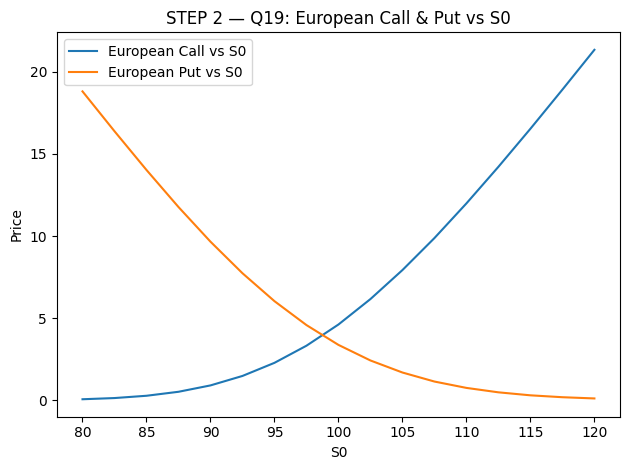


=== STEP 2 — Q20: American Call/Put vs S0 (K=100) ===


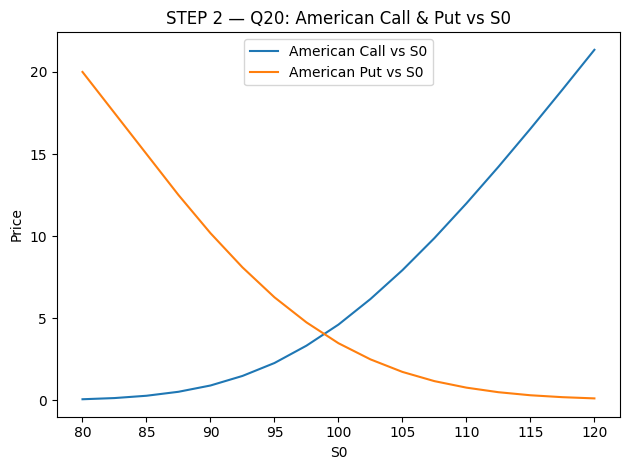


=== STEP 2 — Q21: European vs American CALL vs K ===


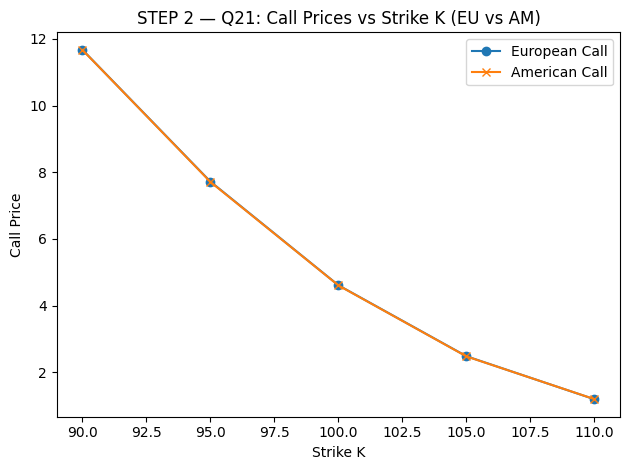


=== STEP 2 — Q22: European vs American PUT vs K ===


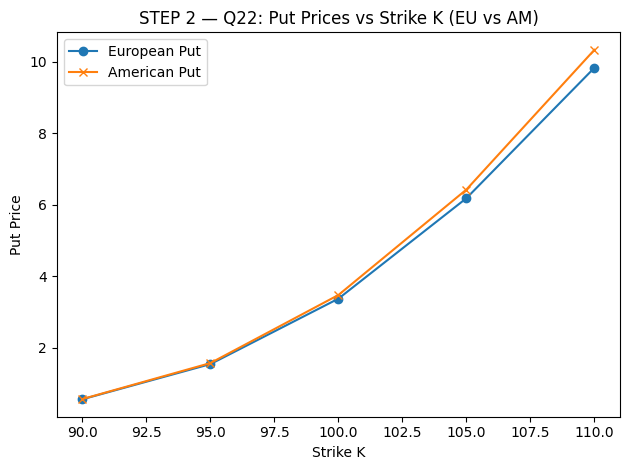


=== STEP 2 — Q23: European Put–Call Parity (per strike) ===
 Q#     K    PV(K)  LHS C_E-P_E  RHS S0-PV(K)  Gap  Holds(|gap|≤0.02)
Q23  90.0  88.8820      11.1180       11.1180  0.0               True
Q23  95.0  93.8199       6.1801        6.1801  0.0               True
Q23 100.0  98.7578       1.2422        1.2422  0.0               True
Q23 105.0 103.6957      -3.6957       -3.6957  0.0               True
Q23 110.0 108.6336      -8.6336       -8.6336  0.0               True

=== STEP 2 — Q24: American Put–Call 'Parity' (per strike) ===
 Q#     K  LHS C_A-P_A  RHS S0-PV(K)     Gap
Q24  90.0      11.1074       11.1180 -0.0106
Q24  95.0       6.1417        6.1801 -0.0384
Q24 100.0       1.1346        1.2422 -0.1076
Q24 105.0      -3.9429       -3.6957 -0.2472
Q24 110.0      -9.1334       -8.6336 -0.4999
Note Q24: Deviations are expected—American puts may be exercised early; calls (no dividends) are not.


In [2]:
# ================================
# STEP 2 — MEMBER C
# Q19: Graph European call/put vs S0 (K=100)
# Q20: Graph American call/put vs S0 (K=100)
# Q21: Graph European vs American CALL vs K
# Q22: Graph European vs American PUT vs K
# Q23: European put–call parity table across the 5 strikes
# Q24: American 'parity' table across the 5 strikes
# - Uses matplotlib for plots (default colors, one figure per chart)
# - Prints tidy tables for Q23 & Q24
# ================================

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----- Engines: European KR & American (moment-matched) -----
def euro_trinomial_price_KR(S0, K, T, r, sigma, N, is_call=True):
    dt = T/N
    u  = math.exp(sigma*math.sqrt(2.0*dt))
    d  = 1.0/u
    pu = ((math.exp(r*dt/2) - math.exp(-sigma*math.sqrt(dt/2))) /
          (math.exp( sigma*math.sqrt(dt/2)) - math.exp(-sigma*math.sqrt(dt/2))))**2
    pd = ((math.exp( sigma*math.sqrt(dt/2)) - math.exp(r*dt/2)) /
          (math.exp( sigma*math.sqrt(dt/2)) - math.exp(-sigma*math.sqrt(dt/2))))**2
    pm = 1.0 - pu - pd
    disc = math.exp(-r*dt)

    stock = [np.zeros(2*j+1) for j in range(N+1)]
    opt   = [np.zeros(2*j+1) for j in range(N+1)]
    stock[0][0] = S0
    for j in range(1,N+1):
        for i in range(2*j+1):
            stock[j][i] = S0*(u**(j-i))

    if is_call:
        opt[N] = np.maximum(0.0, stock[N]-K)
    else:
        opt[N] = np.maximum(0.0, K-stock[N])

    for j in range(N-1,-1,-1):
        for i in range(2*j+1):
            up  = opt[j+1][i]
            mid = opt[j+1][i+1]
            dn  = opt[j+1][i+2]
            opt[j][i] = disc*(pu*up + pm*mid + pd*dn)

    return float(opt[0][0])

def american_trinomial_price(S0, K, T, r, sigma, N, is_call=True):
    dt = T/N; df = math.exp(-r*dt)
    u  = math.exp(sigma*math.sqrt(3.0*dt))
    d  = 1.0/u
    mu = r - 0.5*sigma*sigma
    qu = 1.0/6.0 + (mu*math.sqrt(dt))/(2.0*sigma*math.sqrt(3.0))
    qm = 2.0/3.0
    qd = 1.0 - qu - qm
    if min(qu,qm,qd) < -1e-12:
        raise ValueError("Risk-neutral probabilities out of bounds; increase N.")

    V = {}
    for j in range(-N, N+1):
        S = S0*(u**j) if j>=0 else S0*(d**(-j))
        V[(N,j)] = max(S-K,0.0) if is_call else max(K-S,0.0)

    for n in range(N-1, -1, -1):
        for j in range(-n, n+1):
            S = S0*(u**j) if j>=0 else S0*(d**(-j))
            cont = df*(qu*V[(n+1,j+1)] + qm*V[(n+1,j)] + qd*V[(n+1,j-1)])
            ex   = max(S-K,0.0) if is_call else max(K-S,0.0)
            V[(n,j)] = max(cont, ex)

    return float(V[(0,0)])

# ----- Shared parameters (Step 2 context) -----
S0    = 100.0
r     = 0.05
sigma = 0.20
T     = 0.25
N_eur = 100
N_amer= 100
K_list = [90.0, 95.0, 100.0, 105.0, 110.0]

# ----- Precompute prices across K -----
C_E = [euro_trinomial_price_KR(S0,K_,T,r,sigma,N_eur,True)  for K_ in K_list]
P_E = [euro_trinomial_price_KR(S0,K_,T,r,sigma,N_eur,False) for K_ in K_list]
C_A = [american_trinomial_price(S0,K_,T,r,sigma,N_amer,True)  for K_ in K_list]
P_A = [american_trinomial_price(S0,K_,T,r,sigma,N_amer,False) for K_ in K_list]

# ===== Q19: European vs S0 (K=100) =====
print("\n=== STEP 2 — Q19: European Call/Put vs S0 (K=100) ===")
S_grid = np.linspace(80, 120, 17)
C_E_vsS = [euro_trinomial_price_KR(S, 100.0, T, r, sigma, N_eur, True)  for S in S_grid]
P_E_vsS = [euro_trinomial_price_KR(S, 100.0, T, r, sigma, N_eur, False) for S in S_grid]
import matplotlib.pyplot as plt
plt.figure()
plt.plot(S_grid, C_E_vsS, label="European Call vs S0")
plt.plot(S_grid, P_E_vsS, label="European Put vs S0")
plt.title("STEP 2 — Q19: European Call & Put vs S0")
plt.xlabel("S0"); plt.ylabel("Price"); plt.legend(); plt.tight_layout(); plt.show()

# ===== Q20: American vs S0 (K=100) =====
print("\n=== STEP 2 — Q20: American Call/Put vs S0 (K=100) ===")
C_A_vsS = [american_trinomial_price(S, 100.0, T, r, sigma, N_amer, True)  for S in S_grid]
P_A_vsS = [american_trinomial_price(S, 100.0, T, r, sigma, N_amer, False) for S in S_grid]
plt.figure()
plt.plot(S_grid, C_A_vsS, label="American Call vs S0")
plt.plot(S_grid, P_A_vsS, label="American Put vs S0")
plt.title("STEP 2 — Q20: American Call & Put vs S0")
plt.xlabel("S0"); plt.ylabel("Price"); plt.legend(); plt.tight_layout(); plt.show()

# ===== Q21: Calls vs K (European vs American) =====
print("\n=== STEP 2 — Q21: European vs American CALL vs K ===")
plt.figure()
plt.plot(K_list, C_E, marker="o", label="European Call")
plt.plot(K_list, C_A, marker="x", label="American Call")
plt.title("STEP 2 — Q21: Call Prices vs Strike K (EU vs AM)")
plt.xlabel("Strike K"); plt.ylabel("Call Price"); plt.legend(); plt.tight_layout(); plt.show()

# ===== Q22: Puts vs K (European vs American) =====
print("\n=== STEP 2 — Q22: European vs American PUT vs K ===")
plt.figure()
plt.plot(K_list, P_E, marker="o", label="European Put")
plt.plot(K_list, P_A, marker="x", label="American Put")
plt.title("STEP 2 — Q22: Put Prices vs Strike K (EU vs AM)")
plt.xlabel("Strike K"); plt.ylabel("Put Price"); plt.legend(); plt.tight_layout(); plt.show()

# ===== Q23: European parity table (per strike) =====
print("\n=== STEP 2 — Q23: European Put–Call Parity (per strike) ===")
PVK = [K*math.exp(-r*T) for K in K_list]
lhsE = [c - p for c,p in zip(C_E, P_E)]
rhs  = [S0 - pv for pv in PVK]
gapE = [l - r_ for l,r_ in zip(lhsE, rhs)]
tol  = 0.02
holds = [abs(g) <= tol for g in gapE]
df_q23 = pd.DataFrame({
    "Q#":"Q23","K":K_list,"PV(K)":[round(x,4) for x in PVK],
    "LHS C_E-P_E":[round(x,4) for x in lhsE],
    "RHS S0-PV(K)":[round(x,4) for x in rhs],
    "Gap":[round(x,4) for x in gapE],
    f"Holds(|gap|≤{tol:.2f})":holds
})
print(df_q23.to_string(index=False))

# ===== Q24: American 'parity' table (per strike) =====
print("\n=== STEP 2 — Q24: American Put–Call 'Parity' (per strike) ===")
lhsA = [c - p for c,p in zip(C_A, P_A)]
gapA = [l - r_ for l,r_ in zip(lhsA, rhs)]
df_q24 = pd.DataFrame({
    "Q#":"Q24","K":K_list,
    "LHS C_A-P_A":[round(x,4) for x in lhsA],
    "RHS S0-PV(K)":[round(x,4) for x in rhs],
    "Gap":[round(x,4) for x in gapA]
})
print(df_q24.to_string(index=False))
print("Note Q24: Deviations are expected—American puts may be exercised early; calls (no dividends) are not.")


# Step 3

### Question 26

In [ ]:
import numpy as np
import pandas as pd

def binomial_tree_full(S0, K, T, r, sigma, N, option_type, style):
    # Same as before, but returns full trees
    dt = T / N
    u = np.exp(sigma * np.sqrt(dt))
    d = 1 / u
    p = (np.exp(r * dt) - d) / (u - d)

    stock_tree = np.zeros((N + 1, N + 1))
    option_tree = np.zeros((N + 1, N + 1))
    delta_tree = np.zeros((N, N))
    stock_tree[0, 0] = S0

    for j in range(1, N + 1):
        for i in range(j + 1):
            stock_tree[i, j] = S0 * (u**(j - i)) * (d**i)

    if option_type == 'call':
        option_tree[:, N] = np.maximum(0, stock_tree[:, N] - K)
    else:
        option_tree[:, N] = np.maximum(0, K - stock_tree[:, N])

    for j in range(N - 1, -1, -1):
        for i in range(j + 1):
            hold_value = (p * option_tree[i, j + 1] + (1 - p) * option_tree[i + 1, j + 1]) * np.exp(-r * dt)
            if style == 'american':
                exercise_value = np.maximum(0, K - stock_tree[i, j]) if option_type == 'put' else np.maximum(0, stock_tree[i, j] - K)
                option_tree[i, j] = np.maximum(hold_value, exercise_value)
            else:
                option_tree[i, j] = hold_value
            # Calculate Delta for this node
            delta_tree[i, j] = (option_tree[i, j + 1] - option_tree[i + 1, j + 1]) / (stock_tree[i, j + 1] - stock_tree[i + 1, j + 1])

    return stock_tree, option_tree, delta_tree

# --- Parameters ---
S0_25 = 180
r_25 = 0.02
sigma_25 = 0.25
T_25 = 0.5
K_25 = 182
N_25 = 25

# a. Compute all deltas
stock, option, delta = binomial_tree_full(S0_25, K_25, T_25, r_25, sigma_25, N_25, 'put', 'american')
print(f"--- Question 26 ---")
print(f"a. American Put Price (N=25): ${option[0, 0]:.4f}")
print("a. The full 25x25 delta matrix has been computed.\n")

# b. Trace a path: 13 down, 12 up
path = [1]*13 + [0]*12 # 1=down, 0=up
cash_account = 0
shares_held = 0
current_i = 0

# Initial Hedge
shares_to_hold = delta[0, 0]
cash_account += shares_to_hold * stock[0, 0]
shares_held = shares_to_hold

for t_step in range(N_25):
    # Apply interest
    cash_account *= np.exp(r_25 * (T_25/N_25))

    # Move along path
    current_i += path[t_step]

    # Rebalance
    shares_to_hold = delta[current_i, t_step + 1] if t_step < N_25-1 else 0
    trade_size = shares_to_hold - shares_held
    cash_account += trade_size * stock[current_i, t_step + 1]
    shares_held = shares_to_hold

# Final Settlement
final_S = stock[current_i, N_25]
option_payoff = np.maximum(0, K_25 - final_S)
hedging_cost = option_payoff + cash_account # Cost = Liability + Final Cash

print(f"b. Hedging path: 13 down, 12 up.")
print(f"   Final Stock Price: ${final_S:.2f}")
print(f"   Option Payoff at Expiry (Liability): ${option_payoff:.2f}")
print(f"   Final Cash Account Balance: ${-cash_account:.2f}")
print(f"   Net Hedging Cost: ${hedging_cost:.2f}\n")

--- Question 26 ---
a. American Put Price (N=25): $13.0357
a. The full 25x25 delta matrix has been computed.

b. Hedging path: 13 down, 12 up.
   Final Stock Price: $173.75
   Option Payoff at Expiry (Liability): $8.25
   Final Cash Account Balance: $-3.67
   Net Hedging Cost: $11.92



### Question 27

In [ ]:
import numpy as np
import pandas as pd

# --- Parameters from Q25/Q26 ---
S0_27 = 180
r_27 = 0.02
sigma_27 = 0.25
T_27 = 0.5
N_27 = 25
# For an ATM Asian option, the strike is the initial price
K_27 = 180

# --- Simulation Parameters ---
# Number of sub-simulations for calculating delta at each step.
# NOTE: Higher numbers are more accurate but much slower. 1000 is a reasonable balance.
M_SUB_SIMS = 1000

# --- Helper Function: Prices an Asian Put from an intermediate state ---
def price_asian_put_mc(S_start, T_rem, N_rem, path_sum_so_far, num_prices_in_sum, K, r, sigma, M):
    if T_rem <= 0:
        return np.maximum(0, K - (path_sum_so_far / num_prices_in_sum))

    dt = T_rem / N_rem
    total_prices = num_prices_in_sum + N_rem

    final_payoffs = np.zeros(M)

    # Generate all random numbers at once
    Z = np.random.normal(size=(N_rem, M))

    # Create M paths
    S_paths = np.zeros((N_rem + 1, M))
    S_paths[0, :] = S_start

    for t in range(1, N_rem + 1):
        S_paths[t, :] = S_paths[t-1, :] * np.exp((r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z[t-1, :])

    # For each path, calculate the total average and payoff
    # Sum of future prices (excluding S_start, which is already in path_sum_so_far)
    future_price_sum = np.sum(S_paths[1:, :], axis=0)
    total_sum = path_sum_so_far + future_price_sum
    average_prices = total_sum / total_prices

    final_payoffs = np.maximum(0, K - average_prices)

    # Discounted expected payoff
    price = np.exp(-r * T_rem) * np.mean(final_payoffs)
    return price

# --- Main Hedging Simulation ---
np.random.seed(1) # Set seed for the main path
dt_27 = T_27 / N_27

# 1. Generate the single primary path
main_path_shocks = np.random.normal(size=N_27)
main_path = np.zeros(N_27 + 1)
main_path[0] = S0_27
for t in range(1, N_27 + 1):
    main_path[t] = main_path[t-1] * np.exp((r_27 - 0.5 * sigma_27**2) * dt_27 + sigma_27 * np.sqrt(dt_27) * main_path_shocks[t-1])

# 2. Setup for hedging loop
cash_account = 0
shares_held = 0
path_sum = main_path[0]
num_in_sum = 1
u = np.exp(sigma_27 * np.sqrt(dt_27))
d = 1/u

hedging_data = []

# --- Hedging Loop ---
for t_step in range(N_27):
    # Current state
    S_current = main_path[t_step]
    T_remaining = T_27 - (t_step * dt_27)
    N_remaining = N_27 - t_step

    # Calculate Delta via nested simulation
    # Up-state
    S_up = S_current * u
    price_up = price_asian_put_mc(S_up, T_remaining, N_remaining, path_sum + S_up, num_in_sum + 1, K_27, r_27, sigma_27, M_SUB_SIMS)

    # Down-state
    S_down = S_current * d
    price_down = price_asian_put_mc(S_down, T_remaining, N_remaining, path_sum + S_down, num_in_sum + 1, K_27, r_27, sigma_27, M_SUB_SIMS)

    delta = (price_up - price_down) / (S_up - S_down)

    # Rebalance hedge
    shares_to_hold = delta
    trade_size = shares_to_hold - shares_held

    # Update cash account
    # Interest accrues on previous balance
    cash_account *= np.exp(r_27 * dt_27)
    # Cash flow from trade
    cash_account -= trade_size * S_current

    hedging_data.append([t_step, S_current, shares_held, trade_size, cash_account])

    shares_held = shares_to_hold

    # Update path sum for next step
    path_sum += main_path[t_step+1]
    num_in_sum += 1

# --- Final Settlement ---
final_S = main_path[-1]
# Liquidate final share holdings
cash_account += shares_held * final_S

# Option Payoff (Liability)
final_avg = np.mean(main_path)
option_payoff = np.maximum(0, K_27 - final_avg)

hedging_cost = cash_account
net_pnl = option_payoff - hedging_cost

# --- Print Results ---
df_hedge = pd.DataFrame(hedging_data, columns=['Step', 'Stock Price', 'Shares Held (Delta)', 'Trade Size', 'Cash Account'])
print("--- Question 27: Asian Put Option Hedging ---")
print("b. Evolution of Cash Account (first 5 and last 5 steps):")
print(df_hedge.head().to_string(index=False))
print("...")
print(df_hedge.tail().to_string(index=False))
print("\n--- Final Results ---")
print(f"Final Path Average Stock Price: ${final_avg:.4f}")
print(f"Option Payoff at Expiry (Liability): ${option_payoff:.4f}")
print(f"Final Hedging Cost: ${hedging_cost:.4f}")
print(f"Net P&L (Liability - Hedging Cost): ${-net_pnl:.4f}")

--- Question 27: Asian Put Option Hedging ---
b. Evolution of Cash Account (first 5 and last 5 steps):
 Step  Stock Price  Shares Held (Delta)  Trade Size  Cash Account
    0   180.000000             0.000000   -0.457023     82.264074
    1   190.596977            -0.457023    0.238844     36.774059
    2   186.476882            -0.218179   -0.027261     41.872327
    3   182.985806            -0.245440   -0.059092     52.702023
    4   176.134589            -0.304531   -0.125918     74.901546
...
 Step  Stock Price  Shares Held (Delta)  Trade Size  Cash Account
   20   163.065802            -0.255178    0.038196     34.606457
   21   156.807047            -0.216982    0.025894     30.559924
   22   163.246796            -0.191088    0.043397     23.487810
   23   168.496367            -0.147692    0.036035     17.425477
   24   171.478012            -0.111657    0.036506     11.172393

--- Final Results ---
Final Path Average Stock Price: $172.0334
Option Payoff at Expiry (Liability):

In [4]:
!apt-get install texlive texlive-xetex texlive-latex-extra pandoc
!pip install pypandoc

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  dvisvgm fonts-droid-fallback fonts-lato fonts-lmodern fonts-noto-mono
  fonts-texgyre fonts-urw-base35 libapache-pom-java
  libcmark-gfm-extensions0.29.0.gfm.3 libcmark-gfm0.29.0.gfm.3
  libcommons-logging-java libcommons-parent-java libfontbox-java libgs9
  libgs9-common libidn12 libijs-0.35 libjbig2dec0 libkpathsea6 libpdfbox-java
  libptexenc1 libruby3.0 libsynctex2 libteckit0 libtexlua53 libtexluajit2
  libwoff1 libzzip-0-13 lmodern pandoc-data poppler-data preview-latex-style
  rake ruby ruby-net-telnet ruby-rubygems ruby-webrick ruby-xmlrpc ruby3.0
  rubygems-integration t1utils teckit tex-common tex-gyre texlive-base
  texlive-binaries texlive-fonts-recommended texlive-latex-base
  texlive-latex-recommended texlive-pictures texlive-plain-generic tipa
  xfonts-encodings xfonts-utils
Suggested packages:
  fonts-noto fonts-freefont-

In [5]:
!jupyter nbconvert --to html "GWP1_Group10555.ipynb"

[NbConvertApp] WARNING | pattern 'GWP1_Group10555.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=True]
--execute